In [1]:
import re
import polars as pl
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

In [2]:
from analysis_data import load_analysis_frame

analysis_frame = load_analysis_frame("train")
test_analysis_frame = load_analysis_frame("test")

train_audit = analysis_frame.to_pandas() if hasattr(analysis_frame, "to_pandas") else analysis_frame.copy()
test_audit = test_analysis_frame.to_pandas() if hasattr(test_analysis_frame, "to_pandas") else test_analysis_frame.copy()

target_column = "status_penanganan"

if target_column not in train_audit.columns:
    raise ValueError(f"Kolom target {target_column} tidak ditemukan pada analysis_frame.")

feature_columns = sorted(
    (set(train_audit.columns) & set(test_audit.columns)) - {target_column, "shipment_id"}
)

train_audit = train_audit[feature_columns + [target_column]].copy()
test_audit = test_audit[feature_columns].copy()

print(f"Jumlah fitur train-test yang sama: {len(feature_columns):,}")
print(f"Jumlah baris train: {len(train_audit):,}")
print(f"Jumlah baris test: {len(test_audit):,}")
print(f"Jumlah fitur yang hanya ada di train: {len(set(analysis_frame.columns) - set(test_analysis_frame.columns) - {target_column}):,}")

Jumlah fitur train-test yang sama: 162
Jumlah baris train: 1,243,617
Jumlah baris test: 362,245
Jumlah fitur yang hanya ada di train: 0


In [3]:
feature_inventory = pd.DataFrame({
    "feature": feature_columns,
    "dtype_train": [str(train_audit[col].dtype) for col in feature_columns],
    "dtype_test": [str(test_audit[col].dtype) for col in feature_columns],
    "missing_train": [train_audit[col].isna().mean() for col in feature_columns],
    "missing_test": [test_audit[col].isna().mean() for col in feature_columns],
    "n_unique_train": [train_audit[col].nunique(dropna=True) for col in feature_columns],
    "n_unique_test": [test_audit[col].nunique(dropna=True) for col in feature_columns]
})

display(feature_inventory.head(30))
print(f"Total fitur yang diaudit: {len(feature_inventory):,}")

,feature,dtype_train,dtype_test,missing_train,missing_test,n_unique_train,n_unique_test
0,berat_volumetrik,float32,float32,0.000000,0.000000,8552,6555
1,channel,str,str,0.000000,0.000000,4,4
2,coupon_count,int64,int64,0.000000,0.000000,6,6
3,cour_contract_type,str,str,0.000000,0.000000,3,3
4,cour_courier_score,float32,float32,0.010757,0.010722,5,5
5,cour_experience_years,int64,int64,0.000000,0.000000,9,9
6,cour_hub_id,str,str,0.000000,0.000000,654,654
7,cour_jarak_domisili_hub_km,float32,float32,0.000000,0.000000,378,378
8,cour_kapasitas_muatan_kg,int64,int64,0.000000,0.000000,4,4
9,cour_sertifikasi_hazardous,int64,int64,0.000000,0.000000,2,2


Total fitur yang diaudit: 162


In [4]:
availability_rules = [
    {
        "pattern": r"^(declared_value|distance_km|weight_kg|qty_items|volume_l|is_cod|flag_alamat_baru|ship_month|ship_hour|ship_dow|package_id|promo_id)$",
        "source": "shipment",
        "A": "available",
        "B": "available",
        "C": "available",
        "reason": "Atribut dasar pengiriman yang diasumsikan tercatat saat shipment dibuat."
    },
    {
        "pattern": r"^(customer_id|hub_id)$",
        "source": "shipment_reference",
        "A": "conditional",
        "B": "available",
        "C": "available",
        "reason": "Identitas entitas harus sudah diketahui pada saat prediksi."
    },
    {
        "pattern": r"^(courier_id|cour_shift_code)$",
        "source": "shipment_assignment",
        "A": "conditional",
        "B": "available",
        "C": "available",
        "reason": "Penugasan kurir dapat terjadi setelah shipment dibuat."
    },
    {
        "pattern": r"^cust_",
        "source": "customers",
        "A": "conditional",
        "B": "available",
        "C": "available",
        "reason": "Profil pelanggan dapat tersedia sejak awal, tetapi fitur historis harus dihitung hanya dari data sebelum shipment."
    },
    {
        "pattern": r"^hub_",
        "source": "hubs",
        "A": "conditional",
        "B": "available",
        "C": "available",
        "reason": "Informasi hub bersifat relatif statis, tetapi hub yang relevan harus sudah diketahui."
    },
    {
        "pattern": r"^cour_",
        "source": "couriers",
        "A": "conditional",
        "B": "available",
        "C": "available",
        "reason": "Profil kurir dapat digunakan setelah kurir ditetapkan; skor historis harus bebas dari informasi masa depan."
    },
    {
        "pattern": r"^(pkg_|package_)",
        "source": "service_packages",
        "A": "conditional",
        "B": "available",
        "C": "available",
        "reason": "Informasi paket layanan diasumsikan tersedia ketika layanan dipilih."
    },
    {
        "pattern": r"^(promo_|promotion_)",
        "source": "promotions",
        "A": "conditional",
        "B": "available",
        "C": "available",
        "reason": "Informasi promosi diasumsikan tersedia ketika promosi dipilih."
    },
    {
        "pattern": r"^(sc_n_selesai|sc_.*(delivered|selesai|terkirim|gagal_antar|attempt|percobaan))$",
        "source": "scan_events",
        "A": "unavailable",
        "B": "conditional",
        "C": "conditional",
        "reason": "Status penyelesaian atau percobaan pengantaran dapat merepresentasikan kejadian setelah shipment dibuat."
    },
    {
        "pattern": r"^sc_",
        "source": "scan_events",
        "A": "unavailable",
        "B": "conditional",
        "C": "conditional",
        "reason": "Agregasi scan hanya boleh digunakan jika seluruh event terjadi sebelum waktu prediksi."
    },
    {
        "pattern": r"^rt_",
        "source": "route_segments",
        "A": "unavailable",
        "B": "conditional",
        "C": "conditional",
        "reason": "Segmen dan durasi aktual rute dapat terbentuk selama pengiriman; rute terencana perlu dibedakan dari rute aktual."
    },
    {
        "pattern": r"^(iv_.*(klaim|claim|refund|retur|hilang|rusak|kompensasi))$",
        "source": "invoices",
        "A": "unavailable",
        "B": "unavailable",
        "C": "conditional",
        "reason": "Informasi klaim atau kompensasi berpotensi muncul setelah masalah pengiriman terjadi."
    },
    {
        "pattern": r"^iv_",
        "source": "invoices",
        "A": "conditional",
        "B": "conditional",
        "C": "conditional",
        "reason": "Waktu penerbitan invoice dan pembaruan status pembayaran perlu diverifikasi."
    },
    {
        "pattern": r"^(jumlah_catatan|.*complaint.*|.*catatan.*)$",
        "source": "notes_or_complaints",
        "A": "conditional",
        "B": "conditional",
        "C": "conditional",
        "reason": "Catatan atau komplain dapat dibuat sebelum maupun setelah masalah pengiriman."
    }
]

In [5]:
def classify_feature(feature):
    for rule in availability_rules:
        if re.search(rule["pattern"], feature, flags=re.IGNORECASE):
            return {
                "feature": feature,
                "source_assumption": rule["source"],
                "scenario_A": rule["A"],
                "scenario_B": rule["B"],
                "scenario_C": rule["C"],
                "reason": rule["reason"],
                "matched_rule": rule["pattern"]
            }

    return {
        "feature": feature,
        "source_assumption": "unknown",
        "scenario_A": "unknown",
        "scenario_B": "unknown",
        "scenario_C": "unknown",
        "reason": "Belum memiliki aturan ketersediaan. Perlu pemeriksaan manual.",
        "matched_rule": None
    }

availability_audit = pd.DataFrame(
    [classify_feature(feature) for feature in feature_columns]
)

display(availability_audit.head(30))

,feature,source_assumption,scenario_A,scenario_B,scenario_C,reason,matched_rule
0,berat_volumetrik,unknown,unknown,unknown,unknown,Belum memiliki aturan ketersediaan. Perlu peme...,NaN
1,channel,unknown,unknown,unknown,unknown,Belum memiliki aturan ketersediaan. Perlu peme...,NaN
2,coupon_count,unknown,unknown,unknown,unknown,Belum memiliki aturan ketersediaan. Perlu peme...,NaN
3,cour_contract_type,couriers,conditional,available,available,Profil kurir dapat digunakan setelah kurir dit...,^cour_
4,cour_courier_score,couriers,conditional,available,available,Profil kurir dapat digunakan setelah kurir dit...,^cour_
5,cour_experience_years,couriers,conditional,available,available,Profil kurir dapat digunakan setelah kurir dit...,^cour_
6,cour_hub_id,couriers,conditional,available,available,Profil kurir dapat digunakan setelah kurir dit...,^cour_
7,cour_jarak_domisili_hub_km,couriers,conditional,available,available,Profil kurir dapat digunakan setelah kurir dit...,^cour_
8,cour_kapasitas_muatan_kg,couriers,conditional,available,available,Profil kurir dapat digunakan setelah kurir dit...,^cour_
9,cour_sertifikasi_hazardous,couriers,conditional,available,available,Profil kurir dapat digunakan setelah kurir dit...,^cour_


In [6]:
unknown_features = availability_audit[
    availability_audit["scenario_A"].eq("unknown")
].sort_values("feature")

print(f"Jumlah fitur belum terklasifikasi: {len(unknown_features):,}")
display(unknown_features[["feature", "source_assumption", "reason"]])

Jumlah fitur belum terklasifikasi: 34


,feature,source_assumption,reason
0,berat_volumetrik,unknown,Belum memiliki aturan ketersediaan. Perlu peme...
1,channel,unknown,Belum memiliki aturan ketersediaan. Perlu peme...
2,coupon_count,unknown,Belum memiliki aturan ketersediaan. Perlu peme...
29,dest_region,unknown,Belum memiliki aturan ketersediaan. Perlu peme...
31,faktor_muatan_internal,unknown,Belum memiliki aturan ketersediaan. Perlu peme...
33,fragility_flag,unknown,Belum memiliki aturan ketersediaan. Perlu peme...
34,gift_wrap,unknown,Belum memiliki aturan ketersediaan. Perlu peme...
35,goods_category,unknown,Belum memiliki aturan ketersediaan. Perlu peme...
45,indeks_rute_sekunder,unknown,Belum memiliki aturan ketersediaan. Perlu peme...
46,indeks_waktu_proses,unknown,Belum memiliki aturan ketersediaan. Perlu peme...


In [7]:
scenario_columns = {}

for scenario in ["A", "B", "C"]:
    status_column = f"scenario_{scenario}"

    scenario_columns[f"{scenario}_strict"] = availability_audit.loc[
        availability_audit[status_column].eq("available"),
        "feature"
    ].tolist()

    scenario_columns[f"{scenario}_inclusive"] = availability_audit.loc[
        availability_audit[status_column].isin(["available", "conditional"]),
        "feature"
    ].tolist()

scenario_summary = pd.DataFrame([
    {
        "scenario": "A - Saat shipment dibuat",
        "strict_features": len(scenario_columns["A_strict"]),
        "inclusive_features": len(scenario_columns["A_inclusive"]),
        "conditional_features": int(availability_audit["scenario_A"].eq("conditional").sum()),
        "unavailable_features": int(availability_audit["scenario_A"].eq("unavailable").sum()),
        "unknown_features": int(availability_audit["scenario_A"].eq("unknown").sum())
    },
    {
        "scenario": "B - Saat dalam perjalanan",
        "strict_features": len(scenario_columns["B_strict"]),
        "inclusive_features": len(scenario_columns["B_inclusive"]),
        "conditional_features": int(availability_audit["scenario_B"].eq("conditional").sum()),
        "unavailable_features": int(availability_audit["scenario_B"].eq("unavailable").sum()),
        "unknown_features": int(availability_audit["scenario_B"].eq("unknown").sum())
    },
    {
        "scenario": "C - Setelah percobaan pertama",
        "strict_features": len(scenario_columns["C_strict"]),
        "inclusive_features": len(scenario_columns["C_inclusive"]),
        "conditional_features": int(availability_audit["scenario_C"].eq("conditional").sum()),
        "unavailable_features": int(availability_audit["scenario_C"].eq("unavailable").sum()),
        "unknown_features": int(availability_audit["scenario_C"].eq("unknown").sum())
    }
])

display(scenario_summary)

,scenario,strict_features,inclusive_features,conditional_features,unavailable_features,unknown_features
0,A - Saat shipment dibuat,12,78,66,50,34
1,B - Saat dalam perjalanan,60,126,66,2,34
2,C - Setelah percobaan pertama,60,128,68,0,34


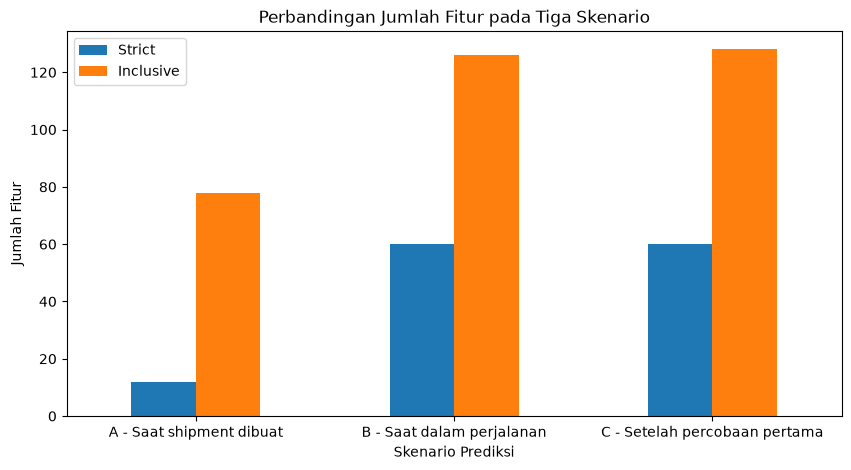

In [8]:
scenario_plot = scenario_summary.set_index("scenario")[
    ["strict_features", "inclusive_features"]
]

ax = scenario_plot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    title="Perbandingan Jumlah Fitur pada Tiga Skenario"
)

ax.set_xlabel("Skenario Prediksi")
ax.set_ylabel("Jumlah Fitur")
ax.legend(["Strict", "Inclusive"])

In [9]:
availability_counts = pd.DataFrame({
    scenario: availability_audit[f"scenario_{scenario}"].value_counts()
    for scenario in ["A", "B", "C"]
}).fillna(0).astype(int)

display(availability_counts)

,A,B,C
available,12,60,60
conditional,66,66,68
unavailable,50,2,0
unknown,34,34,34


In [10]:
risk_patterns = {
    "claim_or_compensation": r"klaim|claim|refund|kompensasi",
    "delivery_completion": r"selesai|terkirim|delivered|completion",
    "delivery_failure": r"gagal_antar|failed_delivery|attempt|percobaan",
    "return_or_loss": r"retur|return|hilang|lost|rusak|damage",
    "payment_update": r"pay_status|payment_status|status_bayar",
    "incident_or_resolution": r"incident|resolution|penanganan|status_akhir"
}

risk_records = []

for feature in feature_columns:
    matched_categories = [
        category
        for category, pattern in risk_patterns.items()
        if re.search(pattern, feature, flags=re.IGNORECASE)
    ]

    if matched_categories:
        risk_records.append({
            "feature": feature,
            "risk_categories": ", ".join(matched_categories),
            "scenario_A": availability_audit.loc[
                availability_audit["feature"].eq(feature), "scenario_A"
            ].iloc[0],
            "scenario_B": availability_audit.loc[
                availability_audit["feature"].eq(feature), "scenario_B"
            ].iloc[0],
            "scenario_C": availability_audit.loc[
                availability_audit["feature"].eq(feature), "scenario_C"
            ].iloc[0]
        })

leakage_candidates = pd.DataFrame(risk_records)

display(leakage_candidates)

,feature,risk_categories,scenario_A,scenario_B,scenario_C
0,iv_amount_klaim,claim_or_compensation,unavailable,unavailable,conditional
1,iv_n_klaim,claim_or_compensation,unavailable,unavailable,conditional
2,sc_n_selesai,delivery_completion,unavailable,conditional,conditional


In [11]:
risk_feature_names = leakage_candidates["feature"].tolist() if len(leakage_candidates) else []

risk_numeric_features = [
    feature
    for feature in risk_feature_names
    if pd.api.types.is_numeric_dtype(train_audit[feature])
]

risk_target_summary = []

for feature in risk_numeric_features:
    grouped = train_audit.groupby(target_column)[feature].agg(
        ["count", "mean", "median", "std"]
    ).reset_index()

    grouped.insert(0, "feature", feature)
    risk_target_summary.append(grouped)

if risk_target_summary:
    risk_target_summary = pd.concat(risk_target_summary, ignore_index=True)
    display(risk_target_summary.sort_values(["feature", "mean"]))
else:
    risk_target_summary = pd.DataFrame()
    print("Tidak ditemukan fitur numerik berisiko untuk dianalisis.")

,feature,status_penanganan,count,mean,median,std
0,iv_amount_klaim,gagal_antar_awal,124341,2347.238642,0.0,5970.021634
5,iv_amount_klaim,rusak_perjalanan,61942,2387.233218,0.0,5990.281038
3,iv_amount_klaim,normal,473531,2504.121166,0.0,6036.431730
6,iv_amount_klaim,tertunda_operasional,185496,2538.076293,0.0,6162.093023
2,iv_amount_klaim,konfirmasi_alamat,272911,2551.538780,0.0,6192.924161
4,iv_amount_klaim,retur_pengirim,87740,5806.302713,0.0,8150.722543
1,iv_amount_klaim,klaim_hilang,37656,6741.794136,0.0,11491.437078
7,iv_n_klaim,gagal_antar_awal,124341,0.149251,0.0,0.356337
12,iv_n_klaim,rusak_perjalanan,61942,0.152239,0.0,0.359255
9,iv_n_klaim,konfirmasi_alamat,272911,0.161884,0.0,0.368345


In [12]:
risk_categorical_features = [
    feature
    for feature in risk_feature_names
    if not pd.api.types.is_numeric_dtype(train_audit[feature])
]

categorical_risk_results = []

for feature in risk_categorical_features:
    temp = train_audit[[feature, target_column]].copy()
    temp[feature] = temp[feature].astype("string").fillna("__MISSING__")

    top_values = temp[feature].value_counts().head(15).index
    temp = temp[temp[feature].isin(top_values)]

    distribution = pd.crosstab(
        temp[feature],
        temp[target_column],
        normalize="index"
    )

    categorical_risk_results.append({
        "feature": feature,
        "distribution": distribution
    })

for result in categorical_risk_results:
    print(f"\nFitur: {result['feature']}")
    display(result["distribution"])

In [13]:
source_table_names = [
    "shipments",
    "scan_events",
    "route_segments",
    "invoices",
    "customers",
    "couriers",
    "hubs"
]

time_keywords = [
    "time", "date", "timestamp", "datetime",
    "tanggal", "waktu", "created", "updated"
]

from analysis_data import DATA_DIR

def table_header(table_name):
    return pl.read_csv(DATA_DIR / "train" / f"{table_name}.csv", n_rows=0).columns

source_time_inventory = []

for table_name in source_table_names:
    columns = table_header(table_name)

    time_columns = [
        column
        for column in columns
        if any(keyword in column.lower() for keyword in time_keywords)
    ]

    source_time_inventory.append({
        "table": table_name,
        "time_columns": time_columns,
        "has_time_column": len(time_columns) > 0
    })

source_time_inventory = pd.DataFrame(source_time_inventory)
display(source_time_inventory)

,table,time_columns,has_time_column
0,shipments,[indeks_waktu_proses],True
1,scan_events,[],False
2,route_segments,[],False
3,invoices,[],False
4,customers,[],False
5,couriers,[],False
6,hubs,[],False


In [14]:
sequence_keywords = ["urutan", "sequence", "order", "event_id"]

sequence_inventory = []

for table_name in ["scan_events", "route_segments"]:
    matched_columns = [
        column
        for column in table_header(table_name)
        if any(keyword in column.lower() for keyword in sequence_keywords)
    ]

    sequence_inventory.append({
        "table": table_name,
        "sequence_columns": matched_columns
    })

sequence_inventory = pd.DataFrame(sequence_inventory)
display(sequence_inventory)

,table,sequence_columns
0,scan_events,[event_id]
1,route_segments,[urutan]


In [15]:
aggregation_patterns = {
    "scan_aggregation": r"^sc_",
    "route_aggregation": r"^rt_",
    "invoice_aggregation": r"^iv_",
    "historical_customer": r"^cust_",
    "historical_courier": r"^cour_",
    "historical_hub": r"^hub_"
}

aggregation_audit = []

for feature in feature_columns:
    categories = [
        category
        for category, pattern in aggregation_patterns.items()
        if re.search(pattern, feature, flags=re.IGNORECASE)
    ]

    if categories:
        aggregation_audit.append({
            "feature": feature,
            "aggregation_type": ", ".join(categories),
            "requires_temporal_validation": True,
            "validation_requirement": "Pastikan agregasi hanya memakai informasi yang tersedia sebelum waktu prediksi."
        })

aggregation_audit = pd.DataFrame(aggregation_audit)
display(aggregation_audit)

,feature,aggregation_type,requires_temporal_validation,validation_requirement
0,cour_contract_type,historical_courier,True,Pastikan agregasi hanya memakai informasi yang...
1,cour_courier_score,historical_courier,True,Pastikan agregasi hanya memakai informasi yang...
2,cour_experience_years,historical_courier,True,Pastikan agregasi hanya memakai informasi yang...
3,cour_hub_id,historical_courier,True,Pastikan agregasi hanya memakai informasi yang...
4,cour_jarak_domisili_hub_km,historical_courier,True,Pastikan agregasi hanya memakai informasi yang...
...,...,...,...,...
94,sc_quality_min,scan_aggregation,True,Pastikan agregasi hanya memakai informasi yang...
95,sc_quality_std,scan_aggregation,True,Pastikan agregasi hanya memakai informasi yang...
96,sc_unique_devices,scan_aggregation,True,Pastikan agregasi hanya memakai informasi yang...
97,sc_unique_event,scan_aggregation,True,Pastikan agregasi hanya memakai informasi yang...


In [16]:
scenario_train_frames = {}
scenario_test_frames = {}

for scenario_name, selected_features in scenario_columns.items():
    scenario_train_frames[scenario_name] = train_audit[
        selected_features + [target_column]
    ].copy()

    scenario_test_frames[scenario_name] = test_audit[
        selected_features
    ].copy()

for scenario_name in scenario_columns:
    print(
        f"{scenario_name}: "
        f"{scenario_train_frames[scenario_name].shape[1] - 1:,} fitur, "
        f"{scenario_train_frames[scenario_name].shape[0]:,} baris train, "
        f"{scenario_test_frames[scenario_name].shape[0]:,} baris test"
    )

A_strict: 12 fitur, 1,243,617 baris train, 362,245 baris test
A_inclusive: 78 fitur, 1,243,617 baris train, 362,245 baris test
B_strict: 60 fitur, 1,243,617 baris train, 362,245 baris test
B_inclusive: 126 fitur, 1,243,617 baris train, 362,245 baris test
C_strict: 60 fitur, 1,243,617 baris train, 362,245 baris test
C_inclusive: 128 fitur, 1,243,617 baris train, 362,245 baris test


In [17]:
scenario_comparison = []

for scenario_name, selected_features in scenario_columns.items():
    scenario_comparison.append({
        "feature_set": scenario_name,
        "feature_count": len(selected_features),
        "features": ", ".join(selected_features)
    })

scenario_comparison = pd.DataFrame(scenario_comparison)
display(scenario_comparison[["feature_set", "feature_count"]])

,feature_set,feature_count
0,A_strict,12
1,A_inclusive,78
2,B_strict,60
3,B_inclusive,126
4,C_strict,60
5,C_inclusive,128


In [18]:
scenario_transition = pd.DataFrame([
    {
        "comparison": "A strict ke B strict",
        "new_features": sorted(
            set(scenario_columns["B_strict"]) -
            set(scenario_columns["A_strict"])
        )
    },
    {
        "comparison": "B strict ke C strict",
        "new_features": sorted(
            set(scenario_columns["C_strict"]) -
            set(scenario_columns["B_strict"])
        )
    },
    {
        "comparison": "A inclusive ke B inclusive",
        "new_features": sorted(
            set(scenario_columns["B_inclusive"]) -
            set(scenario_columns["A_inclusive"])
        )
    },
    {
        "comparison": "B inclusive ke C inclusive",
        "new_features": sorted(
            set(scenario_columns["C_inclusive"]) -
            set(scenario_columns["B_inclusive"])
        )
    }
])

for _, row in scenario_transition.iterrows():
    print(f"\n{row['comparison']}: {len(row['new_features'])} fitur")
    display(pd.DataFrame({"feature": row["new_features"]}))


A strict ke B strict: 48 fitur


,feature
0,cour_contract_type
1,cour_courier_score
2,cour_experience_years
3,cour_hub_id
4,cour_jarak_domisili_hub_km
5,cour_kapasitas_muatan_kg
6,cour_sertifikasi_hazardous
7,cour_shift_code
8,cour_training_level
9,cour_vehicle_type



B strict ke C strict: 0 fitur


,feature



A inclusive ke B inclusive: 48 fitur


,feature
0,rt_cost_mean
1,rt_cost_sum
2,rt_count
3,rt_distance_darat
4,rt_distance_kereta
5,rt_distance_laut
6,rt_distance_max
7,rt_distance_mean
8,rt_distance_sum
9,rt_distance_udara



B inclusive ke C inclusive: 2 fitur


,feature
0,iv_amount_klaim
1,iv_n_klaim


In [19]:
output_dir = Path("section08_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

feature_inventory.to_csv(
    output_dir / "feature_inventory.csv",
    index=False
)

availability_audit.to_csv(
    output_dir / "feature_availability_audit.csv",
    index=False
)

scenario_summary.to_csv(
    output_dir / "scenario_summary.csv",
    index=False
)

leakage_candidates.to_csv(
    output_dir / "leakage_candidates.csv",
    index=False
)

aggregation_audit.to_csv(
    output_dir / "aggregation_temporal_audit.csv",
    index=False
)

source_time_inventory.to_csv(
    output_dir / "source_time_inventory.csv",
    index=False
)

sequence_inventory.to_csv(
    output_dir / "sequence_inventory.csv",
    index=False
)

for scenario_name, selected_features in scenario_columns.items():
    pd.DataFrame({"feature": selected_features}).to_csv(
        output_dir / f"{scenario_name}_features.csv",
        index=False
    )

print(f"Seluruh hasil audit tersimpan di: {output_dir.resolve()}")

Seluruh hasil audit tersimpan di: C:\Users\ASUS\.vscode\arkavidia\section08_outputs
